<a href="https://colab.research.google.com/github/<YOUR-GITHUB-USERNAME>/scikit-learn-cookbook/blob/main/01.%20API%20Elements%20of%20scikit-learn/ch01_sklearn_api.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 1: Common Conventions and API Elements of scikit-learn

scikit-learn started in 2007 as a Google Summer of Code project and was first released publicly in 2010. Despite its age, it remains the most widely used general-purpose machine learning (ML) library in Python for research, teaching, and production work. A large part of that success is **not** the number of algorithms it contains, but the **consistency of its API**: once you have learned how one estimator behaves, you can use almost any other estimator in the library without reading new documentation.

This chapter explains the conventions that make that possible. Every later chapter in this repository relies on them.

**What this notebook covers**

1. The design philosophy of scikit-learn (consistency, inspection, composition, sensible defaults)
2. **Estimators** and the `fit()` / `predict()` / `score()` contract
3. **Transformers** and the `fit()` / `transform()` / `fit_transform()` contract, including why *data leakage* happens
4. **Custom estimators and transformers** built with `BaseEstimator` and mixin classes
5. **Pipelines** and workflow automation (`Pipeline`, `make_pipeline`, `ColumnTransformer`)
6. Common **attributes and methods** shared by estimators (`coef_`, `feature_importances_`, `classes_`, `score()`, ...)
7. **Hyperparameter tuning** with search methods (`GridSearchCV`, `RandomizedSearchCV`, successive halving)
8. **Metadata**: estimator tags and metadata routing
9. **Best practices** for API usage

> **Reference:** *scikit-learn Cookbook, Third Edition* (John Sukup, Packt Publishing), Chapter 1. All code below was executed with the library versions printed in the first code cell. Beyond the book's examples, each section adds manual verifications and small experiments to show *why* the API behaves the way it does.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

print(f"scikit-learn version: {sklearn.__version__}")
print(f"NumPy version:        {np.__version__}")
print(f"pandas version:       {pd.__version__}")

scikit-learn version: 1.8.0
NumPy version:        2.4.4
pandas version:       3.0.2


This chapter has no special technical requirements other than a working Python environment with `scikit-learn`, `numpy`, `pandas`, and `matplotlib`. If you want to run the notebook locally, create a virtual environment first (for example `python -m venv .venv`) so that library versions do not clash with other projects.

## 1. scikit-learn's Design Philosophy

The scikit-learn API was designed around a small number of principles (described in the paper *"API design for machine learning software: experiences from the scikit-learn project"*, Buitinck et al., 2013):

| Principle | Meaning | Practical consequence |
|:----------|:--------|:----------------------|
| **Consistency** | All objects share a limited set of methods with the same names and semantics | `fit()`, `predict()`, `transform()` work the same way for every algorithm |
| **Inspection** | Hyperparameters and learned values are exposed as public attributes | `model.get_params()`, `model.coef_` |
| **Non-proliferation of classes** | Datasets are NumPy arrays / SciPy sparse matrices / pandas DataFrames, not custom classes | No library-specific data container to learn |
| **Composition** | Existing building blocks are combined, rather than re-implemented | `Pipeline`, `ColumnTransformer`, `GridSearchCV` wrap other estimators |
| **Sensible defaults** | Every hyperparameter has a reasonable default | `LogisticRegression()` works out of the box |

Two practical corollaries are worth memorising now because they appear throughout the book:

- **Hyperparameters** (set *before* training, e.g. `n_neighbors=5`) are passed to `__init__` and are stored **unchanged**.
- **Learned parameters** (computed *during* `fit()`, e.g. coefficients) are stored in attributes that **end with an underscore**, such as `coef_` or `classes_`.

> **Capitalisation note.** The library name is always written in lower case: *scikit-learn*. It is pronounced "sy-kit", where *sci* is short for *science*, i.e. a (data) science kit.

### 1.1 The same interface across very different algorithms

The following experiment trains four algorithms that have nothing in common mathematically (a linear model, a distance-based model, a single tree, and an ensemble of trees) using **exactly the same four lines of code**. This is the consistency principle in action.

In [2]:
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

X, y = load_diabetes(return_X_y=True)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

models = {
    "LinearRegression":      LinearRegression(),
    "KNeighborsRegressor":   KNeighborsRegressor(n_neighbors=5),
    "DecisionTreeRegressor": DecisionTreeRegressor(max_depth=4, random_state=42),
    "RandomForestRegressor": RandomForestRegressor(n_estimators=100, random_state=42),
}

rows = []
for name, model in models.items():
    model.fit(X_train, y_train)                 # 1) learn from training data
    y_pred = model.predict(X_test)              # 2) predict on unseen data
    r2 = model.score(X_test, y_test)            # 3) default metric (R^2 for regressors)
    rows.append({"model": name, "test R^2": r2})

pd.DataFrame(rows).set_index("model")

,test R^2
model,
LinearRegression,0.4526
KNeighborsRegressor,0.4302
DecisionTreeRegressor,0.3264
RandomForestRegressor,0.4428


Four completely different algorithms were trained and evaluated by a single loop, because they all obey the same contract. This is why it is so easy in scikit-learn to **swap models** while comparing them: the surrounding code does not change.

The ranking above is only illustrative (one random split of a small dataset); proper model comparison needs cross-validation, which we introduce in later chapters.

## 2. Understanding Estimators

An **estimator** is any object that *learns from data*. It is the central concept of the library. Technically, an estimator is a Python object that implements a `fit()` method. Depending on its role it also implements:

| Method | Role | Implemented by |
|:-------|:-----|:---------------|
| `fit(X, y=None)` | Learn parameters from data and return `self` | **All** estimators |
| `predict(X)` | Produce predictions for new samples | Predictors (classifiers, regressors, clusterers) |
| `score(X, y)` | Return a default quality score | Most predictors |
| `transform(X)` | Return a modified version of `X` | Transformers |
| `fit_predict(X)` | `fit` then `predict` on the same data | Mostly clusterers |
| `fit_transform(X)` | `fit` then `transform` on the same data | Transformers |

### 2.1 `fit()` and `predict()` with `LinearRegression`

We reproduce the book's example. The data follow an approximately linear relationship, $y \approx x$, with small deviations.

In [3]:
from sklearn.linear_model import LinearRegression

# Example data from the book
X = np.array([[1], [2], [3], [4], [5]])      # feature matrix: shape (n_samples, n_features)
y = np.array([1, 2, 3, 3.5, 5])              # target vector:  shape (n_samples,)

model = LinearRegression()
model.fit(X, y)

X_new = np.array([[6], [7]])
predictions = model.predict(X_new)
print("Predictions for x = 6 and x = 7:", predictions)
print("X shape:", X.shape, "| y shape:", y.shape)

Predictions for x = 6 and x = 7: [5.75 6.7 ]
X shape: (5, 1) | y shape: (5,)


Two shape conventions are used everywhere in scikit-learn:

- `X` is always **two-dimensional** with shape `(n_samples, n_features)`, even when there is only one feature. Passing a 1-D array raises an error; use `X.reshape(-1, 1)` to convert.
- `y` is **one-dimensional** with shape `(n_samples,)` for single-output problems.

Let's verify that `predict()` is nothing more than the linear equation $\hat{y} = \beta_0 + \beta_1 x$ evaluated with the learned parameters.

In [4]:
slope = model.coef_[0]
intercept = model.intercept_
manual = intercept + slope * X_new.ravel()

print(f"Learned slope (coef_):        {slope:.4f}")
print(f"Learned intercept (intercept_): {intercept:.4f}")
print("Manual prediction:   ", manual)
print("model.predict output:", predictions)
print("Identical:", np.allclose(manual, predictions))

Learned slope (coef_):        0.9500
Learned intercept (intercept_): 0.0500
Manual prediction:    [5.75 6.7 ]
model.predict output: [5.75 6.7 ]
Identical: True


The manual calculation matches `predict()` exactly. A fitted estimator is therefore just an object that *stores learned numbers* (here `coef_` and `intercept_`) and knows how to apply them.

### 2.2 Hyperparameters versus learned parameters

Everything passed to the constructor is a **hyperparameter**; everything learned by `fit()` has a **trailing underscore**. We can list both programmatically.

In [5]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

X_iris, y_iris = load_iris(return_X_y=True)
rf = RandomForestClassifier(n_estimators=50, max_depth=3, random_state=0)

print("Hyperparameters BEFORE fit (subset):")
for k in ["n_estimators", "max_depth", "criterion", "random_state"]:
    print(f"  {k:14s} = {rf.get_params()[k]}")

rf.fit(X_iris, y_iris)

learned = [a for a in dir(rf) if a.endswith("_") and not a.startswith("_")]
print("\nLearned attributes AFTER fit (trailing underscore):")
print(" ", learned)

Hyperparameters BEFORE fit (subset):
  n_estimators   = 50
  max_depth      = 3
  criterion      = gini
  random_state   = 0

Learned attributes AFTER fit (trailing underscore):
  ['classes_', 'estimator_', 'estimators_', 'estimators_samples_', 'feature_importances_', 'n_classes_', 'n_features_in_', 'n_outputs_']


Before `fit()` none of these underscore attributes exist, which is a handy way to tell whether an estimator has been trained. scikit-learn provides `check_is_fitted()` for the same purpose, and raises `NotFittedError` when you call `predict()` too early.

In [6]:
from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

fresh = LinearRegression()
try:
    fresh.predict(X_new)
except NotFittedError as e:
    print("NotFittedError raised as expected:")
    print(" ", str(e)[:110], "...")

try:
    check_is_fitted(fresh)
except NotFittedError:
    print("check_is_fitted(fresh) -> not fitted")

check_is_fitted(model)    # no exception: model was fitted above
print("check_is_fitted(model) -> OK, the estimator is fitted")

NotFittedError raised as expected:
  This LinearRegression instance is not fitted yet. Call 'fit' with appropriate arguments before using this esti ...
check_is_fitted(fresh) -> not fitted
check_is_fitted(model) -> OK, the estimator is fitted


### 2.3 `fit()` returns `self`: method chaining

`fit()` always returns the estimator itself. This allows compact one-liners such as `LinearRegression().fit(X, y).predict(X_new)`, which you will often see in the wild.

In [7]:
chained = LinearRegression().fit(X, y).predict(X_new)
print("Chained prediction:", chained)
print("fit() returns the estimator itself:", isinstance(LinearRegression().fit(X, y), LinearRegression))

Chained prediction: [5.75 6.7 ]
fit() returns the estimator itself: True


### 2.4 `fit_predict()` and unsupervised learning

For **supervised** learning we fit on a training set and predict on a *different* hold-out set, so `fit()` and `predict()` are separate calls. For many **unsupervised** algorithms (especially clustering) the goal is to label the very data we trained on. `fit_predict()` combines both steps.

Note that there is no target variable `y` here; the algorithm discovers the structure by itself.

In [8]:
from sklearn.cluster import KMeans

X_cluster = np.array([[1], [2], [3], [4], [5]])
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
labels = kmeans.fit_predict(X_cluster)

print("Cluster labels:", labels)
print("Cluster centers:", kmeans.cluster_centers_.ravel())
print("Inertia (sum of squared distances to centres): %.3f" % kmeans.inertia_)

Cluster labels: [0 0 0 1 1]
Cluster centers: [2.  4.5]
Inertia (sum of squared distances to centres): 2.500


The five points are split into a group of low values and a group of high values. The cluster **label numbers themselves (0 or 1) are arbitrary** and may be swapped between runs or random seeds; only the grouping is meaningful.

Datasets can still be split into train/validation/test sets for unsupervised problems (for instance to check that clusters generalise to new data). In that case you would call `fit()` on the training set and `predict()` on the held-out set, exactly as in the supervised case.

Throughout the book we meet many estimators: `LinearRegression` (Chapter 5), `KNeighborsClassifier` (Chapter 4), `DecisionTreeClassifier` (Chapter 8), and so on. All of them follow the pattern above.

### 2.5 The default `score()` method

`score(X, y)` returns a default metric which depends on the estimator type:

| Estimator type | Default `score()` |
|:---------------|:------------------|
| Classifier | Accuracy: $\frac{\text{correct predictions}}{\text{all predictions}}$ |
| Regressor | Coefficient of determination: $R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$ |

Let's verify the regressor formula by hand.

In [9]:
y_hat = model.predict(X)
ss_res = np.sum((y - y_hat) ** 2)
ss_tot = np.sum((y - y.mean()) ** 2)
r2_manual = 1 - ss_res / ss_tot

print(f"R^2 from model.score : {model.score(X, y):.6f}")
print(f"R^2 computed by hand : {r2_manual:.6f}")

R^2 from model.score : 0.980978
R^2 computed by hand : 0.980978


## 3. Transformers and the `transform()` Method

A **transformer** is an estimator that modifies data (scaling, encoding, imputing, selecting features, reducing dimensionality, ...). It follows a two-step contract:

1. `fit(X)` **learns** transformation parameters from the data (for example a mean and a standard deviation).
2. `transform(X)` **applies** the learned parameters to any data.

`fit_transform(X)` is a shortcut that performs both steps in one call (and can be more efficient for some transformers).

### 3.1 `StandardScaler` step by step

`StandardScaler` learns the mean $\mu$ and standard deviation $\sigma$ of every column and then computes the **z-score**:

$$z = \frac{x - \mu}{\sigma}$$

In [10]:
from sklearn.preprocessing import StandardScaler

X_t = np.array([[1, 2], [3, 4], [5, 6]], dtype=float)

scaler = StandardScaler()
scaler.fit(X_t)                    # learn mu and sigma per column
X_scaled = scaler.transform(X_t)   # apply them

print("Learned means  (mean_):", scaler.mean_)
print("Learned stds   (scale_):", scaler.scale_)
print("\nScaled data:\n", X_scaled)

# Manual z-score check
manual_z = (X_t - X_t.mean(axis=0)) / X_t.std(axis=0, ddof=0)
print("\nManual z-score matches:", np.allclose(manual_z, X_scaled))

Learned means  (mean_): [3. 4.]
Learned stds   (scale_): [1.63299316 1.63299316]

Scaled data:
 [[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]

Manual z-score matches: True


Note that scikit-learn uses the **population** standard deviation (`ddof=0`) when scaling, not the sample standard deviation (`ddof=1`) used by `pandas.DataFrame.std()` by default. This small difference explains why a manual calculation with pandas may not match exactly.

The `fit_transform()` shortcut gives the same result in a single call:

In [11]:
X_scaled_2 = StandardScaler().fit_transform(X_t)
print(X_scaled_2)
print("Same as fit() + transform():", np.allclose(X_scaled, X_scaled_2))

# Transformations are reversible when the transformer stores its parameters
X_back = scaler.inverse_transform(X_scaled)
print("\ninverse_transform recovers the original data:", np.allclose(X_back, X_t))

[[-1.22474487 -1.22474487]
 [ 0.          0.        ]
 [ 1.22474487  1.22474487]]
Same as fit() + transform(): True

inverse_transform recovers the original data: True


### 3.2 Why we never call `fit()` on the test set: data leakage

When we apply a transformer to a train/test split we must follow one rule:

> **`fit` (or `fit_transform`) on the training data only. Then `transform` the test data with the *already learned* parameters.**

Re-fitting the transformer on the test set would compute a *different* mean and standard deviation. That is wrong for two reasons: (a) the test data would be transformed differently from the training data the model learned from, and (b) in production you will often receive **one sample at a time**, for which a mean and standard deviation cannot even be estimated.

A subtler version of the same mistake is fitting the transformer on the **whole dataset before splitting**. Information from the test rows then leaks into the training process; this is called **data leakage**. The next cell demonstrates the first mistake concretely.

In [12]:
rng = np.random.default_rng(0)
X_tr = rng.normal(loc=50, scale=10, size=(100, 1))       # training data
X_te = rng.normal(loc=55, scale=12, size=(30, 1))        # slightly different test data

# CORRECT: learn from train, apply to test
sc_ok = StandardScaler().fit(X_tr)
te_correct = sc_ok.transform(X_te)

# WRONG: re-fit on the test set
te_wrong = StandardScaler().fit_transform(X_te)

print(f"Train mean/std used by the correct scaler : {sc_ok.mean_[0]:.2f} / {sc_ok.scale_[0]:.2f}")
print(f"Test data after CORRECT transform -> mean {te_correct.mean():+.3f}, std {te_correct.std():.3f}")
print(f"Test data after WRONG  re-fit     -> mean {te_wrong.mean():+.3f}, std {te_wrong.std():.3f}")

Train mean/std used by the correct scaler : 50.81 / 9.62
Test data after CORRECT transform -> mean +0.363, std 1.124
Test data after WRONG  re-fit     -> mean +0.000, std 1.000


The correct approach correctly reveals that the test data are shifted relative to the training data (the mean is not zero). The wrong approach silently **hides** the shift by forcing the test data to have mean 0 and standard deviation 1, which makes a model trained on the original scale behave unpredictably and makes the evaluation unrealistic.

This consistency is exactly what pipelines (Section 5) guarantee automatically.

### 3.3 Other transformers you will meet in this book

All of these use the identical `fit` / `transform` interface:

| Transformer | Purpose | Chapter |
|:------------|:--------|:-------:|
| `StandardScaler`, `MinMaxScaler`, `Normalizer` | Rescale features | 2 |
| `SimpleImputer`, `KNNImputer`, `IterativeImputer` | Fill missing values | 2 |
| `OneHotEncoder`, `OrdinalEncoder` | Encode categories | 2 |
| `PolynomialFeatures`, `KBinsDiscretizer` | Create new features | 2, 5 |
| `PCA`, `LinearDiscriminantAnalysis` | Reduce dimensionality | 3 |
| `TfidfVectorizer`, `CountVectorizer` | Convert text to numbers | 9 |

A short preview showing that two very different transformers expose the same methods:

In [13]:
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

# Numeric transformer
mm = MinMaxScaler().fit(X_t)
print("MinMaxScaler output:\n", mm.transform(X_t))

# Categorical transformer
colors = np.array([["red"], ["green"], ["blue"], ["green"]])
ohe = OneHotEncoder(sparse_output=False).fit(colors)
print("\nOneHotEncoder categories_:", ohe.categories_[0])
print(ohe.transform(colors))

MinMaxScaler output:
 [[0.  0. ]
 [0.5 0.5]
 [1.  1. ]]

OneHotEncoder categories_: ['blue' 'green' 'red']
[[0. 0. 1.]
 [0. 1. 0.]
 [1. 0. 0.]
 [0. 1. 0.]]


## 4. Handling Custom Estimators and Transformers

scikit-learn is built to be **extended**. If you write a class that follows the estimator conventions, it becomes a first-class citizen: it works inside `Pipeline`, can be cloned, tuned with `GridSearchCV`, and cross-validated like a built-in estimator.

The recipe is:

1. Inherit from `BaseEstimator`. This provides `get_params()` / `set_params()` and a readable `repr`, as long as the constructor only **stores its arguments unchanged** under the same names.
2. Inherit from a **mixin** that provides the behaviour you want:
   - `TransformerMixin` adds `fit_transform()` (built from your `fit()` and `transform()`)
   - `ClassifierMixin` adds `score()` returning accuracy
   - `RegressorMixin` adds `score()` returning $R^2$
3. Implement `fit()` (returning `self`) and `transform()` or `predict()`.
4. Store learned values in attributes **ending with an underscore**.

> **What is a mixin?** A mixin is a small class that adds a specific piece of functionality to other classes through multiple inheritance, without being a standalone base class. Instead of copying the same `score()` method into every classifier, scikit-learn provides it once in `ClassifierMixin`, and every classifier simply includes it. In current scikit-learn versions, **mixins must be listed before `BaseEstimator`** in the base-class list, because tag resolution follows Python's method resolution order (MRO).

### 4.1 A custom transformer: an IQR-based outlier clipper

The transformer below learns, for each feature, the interquartile range during `fit()` and clips extreme values in `transform()`:

$$\text{lower} = Q_1 - k \cdot \text{IQR}, \qquad \text{upper} = Q_3 + k \cdot \text{IQR}, \qquad \text{IQR} = Q_3 - Q_1$$

where $k$ is a hyperparameter (the classical boxplot value is $k=1.5$).

In [14]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted

class IQRClipper(TransformerMixin, BaseEstimator):
    # Clips every feature to [Q1 - k*IQR, Q3 + k*IQR] learned on the training data

    def __init__(self, k=1.5):
        self.k = k                      # hyperparameter: stored unchanged

    def fit(self, X, y=None):
        X = check_array(X)              # validates shape, dtype, NaN/inf
        q1, q3 = np.percentile(X, [25, 75], axis=0)
        iqr = q3 - q1
        self.lower_ = q1 - self.k * iqr # learned values end with "_"
        self.upper_ = q3 + self.k * iqr
        self.n_features_in_ = X.shape[1]
        return self                     # always return self

    def transform(self, X):
        check_is_fitted(self, ["lower_", "upper_"])
        X = check_array(X)
        if X.shape[1] != self.n_features_in_:
            raise ValueError(f"Expected {self.n_features_in_} features, got {X.shape[1]}")
        return np.clip(X, self.lower_, self.upper_)

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None
                          else [f"x{i}" for i in range(self.n_features_in_)], dtype=object)

# Data with one extreme outlier
rng = np.random.default_rng(1)
X_o = rng.normal(0, 1, size=(200, 2))
X_o[0, 0] = 40.0                                  # an outlier of 40 sigma

clipper = IQRClipper(k=1.5)
X_clipped = clipper.fit_transform(X_o)            # fit_transform comes for free from TransformerMixin

print(clipper)                                    # repr works thanks to BaseEstimator
print("Learned lower_:", np.round(clipper.lower_, 3))
print("Learned upper_:", np.round(clipper.upper_, 3))
print(f"Max of feature 0 before: {X_o[:,0].max():.2f} | after clipping: {X_clipped[:,0].max():.2f}")

IQRClipper()
Learned lower_: [-2.53  -2.422]
Learned upper_: [2.297 2.403]
Max of feature 0 before: 40.00 | after clipping: 2.30


With about 15 lines of code we obtained a transformer that has `fit_transform()`, `get_params()`, `set_params()`, a clean `repr`, and the ability to be cloned. Because `BaseEstimator` inspects the signature of `__init__`, `get_params()` automatically reports `k`.

We can see the mixin machinery directly by printing the method resolution order:

In [15]:
print("MRO of IQRClipper:")
for cls in IQRClipper.__mro__:
    print("  ", cls.__name__)

print("\nget_params():", clipper.get_params())
print("set_params(k=3.0) returns the estimator:", clipper.set_params(k=3.0))

MRO of IQRClipper:
   IQRClipper
   TransformerMixin
   _SetOutputMixin
   BaseEstimator
   ReprHTMLMixin
   _HTMLDocumentationLinkMixin
   _MetadataRequester
   object

get_params(): {'k': 1.5}
set_params(k=3.0) returns the estimator: IQRClipper(k=3.0)


### 4.2 A custom classifier: nearest centroid

To illustrate a custom **predictor** we implement a very simple classifier. During `fit()` it computes the mean vector (centroid) of each class; during `predict()` it assigns every sample to the class whose centroid is closest in Euclidean distance. `ClassifierMixin` provides `score()` (accuracy) for free.

In [16]:
from sklearn.base import ClassifierMixin

class SimpleCentroidClassifier(ClassifierMixin, BaseEstimator):
    def fit(self, X, y):
        X = check_array(X)
        y = np.asarray(y)
        self.classes_ = np.unique(y)
        self.centroids_ = np.vstack([X[y == c].mean(axis=0) for c in self.classes_])
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        check_is_fitted(self, ["classes_", "centroids_"])
        X = check_array(X)
        # distance of every sample to every centroid -> shape (n_samples, n_classes)
        d = np.linalg.norm(X[:, None, :] - self.centroids_[None, :, :], axis=2)
        return self.classes_[np.argmin(d, axis=1)]

from sklearn.datasets import load_wine
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import NearestCentroid

Xw, yw = load_wine(return_X_y=True)
Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(Xw, yw, test_size=0.25, random_state=0, stratify=yw)

mine = make_pipeline(StandardScaler(), SimpleCentroidClassifier()).fit(Xw_tr, yw_tr)
ref  = make_pipeline(StandardScaler(), NearestCentroid()).fit(Xw_tr, yw_tr)

print(f"Custom classifier accuracy (score from ClassifierMixin): {mine.score(Xw_te, yw_te):.4f}")
print(f"Built-in NearestCentroid accuracy                      : {ref.score(Xw_te, yw_te):.4f}")
print("Identical predictions:", np.array_equal(mine.predict(Xw_te), ref.predict(Xw_te)))

Custom classifier accuracy (score from ClassifierMixin): 0.9778
Built-in NearestCentroid accuracy                      : 0.9778


Identical predictions: True


Our hand-written classifier reproduces the built-in `NearestCentroid` exactly and it plugs into `make_pipeline` without any adaptation. In the same way it can be passed to `GridSearchCV`, `cross_val_score`, and any other meta-estimator, because those only rely on the conventions described above.

Parameter validation is part of good estimator design: `check_array()` rejects NaN/infinite values and wrong shapes, and `check_is_fitted()` prevents using an untrained object. For production-grade estimators scikit-learn also ships `sklearn.utils.estimator_checks`, a test-suite that verifies compliance with the API.

We will cover custom components again in later chapters when we discuss deployment.

## 5. Pipelines and Workflow Automation

An ML workflow is usually a **sequence of steps**: impute missing values, scale, encode, select features, train a model, predict. A `Pipeline` chains these steps into **a single estimator**. Everything we learned above applies to the pipeline itself: it has `fit()`, `predict()`, `score()`, can be cloned, cross-validated and tuned as a whole.

**Why use pipelines?**

| Benefit | Explanation |
|:--------|:------------|
| Correct order | Steps always execute in the order defined |
| No data leakage | During cross-validation each step is re-fitted on the training folds only |
| Less code | One object instead of many intermediate variables |
| Tuning everything at once | Preprocessing choices become hyperparameters (`step__param`) |
| Reproducibility & deployment | One object to save with `joblib` and ship |

All steps except the last must be **transformers**; the last step can be a transformer or a predictor.

> **MLOps context.** In machine learning operations (MLOps) practice, ML systems are not a one-off script but a cycle of data collection, training, deployment, monitoring and retraining (often automated with CI/CD). Pipelines are the unit that makes this repeatable. scikit-learn integrates with tools such as `joblib` (persistence), MLflow, and Kubeflow. We return to deployment in Chapter 13.

### 5.1 Building and inspecting a pipeline

We use the breast-cancer dataset that ships with scikit-learn.

In [17]:
from sklearn.datasets import load_breast_cancer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn import set_config

bc = load_breast_cancer(as_frame=True)
Xb, yb = bc.data, bc.target
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(Xb, yb, test_size=0.2, random_state=42, stratify=yb)

pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler",  StandardScaler()),
    ("clf",     LogisticRegression(max_iter=1000)),
])

pipe.fit(Xb_tr, yb_tr)
print("Pipeline test accuracy:", round(pipe.score(Xb_te, yb_te), 4))
print("Step names:", list(pipe.named_steps))
print("Scaler mean of first 3 features:", np.round(pipe.named_steps["scaler"].mean_[:3], 3))
print("Number of logistic-regression coefficients:", pipe.named_steps["clf"].coef_.shape[1])

Pipeline test accuracy: 0.9825
Step names: ['imputer', 'scaler', 'clf']
Scaler mean of first 3 features: [14.067 19.247 91.557]
Number of logistic-regression coefficients: 30


`pipe.fit()` calls `fit_transform()` on every transformer in turn (each step receives the output of the previous one) and finally `fit()` on the last estimator. `pipe.predict()` and `pipe.score()` call `transform()` on the transformers and `predict()`/`score()` on the final estimator. We never touched the intermediate arrays ourselves, so it is impossible to forget to scale the test data.

### 5.2 Visualising the pipeline

`set_config(display="diagram")` makes Jupyter render an interactive diagram of the object (click on a box to expand it).

In [18]:
set_config(display="diagram")
pipe

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account for missingness despite imputation. I

### 5.3 `make_pipeline`, step access and slicing

`make_pipeline()` is a shorthand that names the steps automatically (lower-case class names). Pipelines can be indexed and sliced like lists, which is useful to look at the data *between* steps.

In [19]:
quick = make_pipeline(SimpleImputer(), StandardScaler(), LogisticRegression(max_iter=1000))
print("Auto-generated step names:", [name for name, _ in quick.steps])

quick.fit(Xb_tr, yb_tr)

# Slice: everything except the final estimator -> a transformer-only pipeline
preprocessor = quick[:-1]
Z = preprocessor.transform(Xb_te)
print("\nPreprocessed test matrix shape:", Z.shape)
print("Column means of preprocessed test data (not exactly 0, because the scaler used TRAIN stats):")
print(np.round(Z.mean(axis=0)[:5], 3))
print("\nFinal estimator:", quick[-1])

Auto-generated step names: ['simpleimputer', 'standardscaler', 'logisticregression']

Preprocessed test matrix shape: (114, 30)
Column means of preprocessed test data (not exactly 0, because the scaler used TRAIN stats):
[0.086 0.048 0.085 0.092 0.072]

Final estimator: LogisticRegression(max_iter=1000)


### 5.4 Pipelines prevent leakage during cross-validation

The biggest practical benefit appears inside cross-validation. Compare two evaluation strategies:

- **Leaky**: scale the whole dataset first, then cross-validate. Each validation fold has already influenced the scaler.
- **Correct**: put the scaler *inside* a pipeline, so it is re-fitted on the training folds of each split.

With a well-behaved dataset the difference is small, but the principle is vital. To make the damage of leakage visible, the experiment below uses a pathological case: **feature selection on pure noise**. Labels are random, so a fair estimate of accuracy must be about 50%.

In [20]:
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score, StratifiedKFold

rng = np.random.default_rng(7)
X_noise = rng.normal(size=(60, 2000))       # 60 samples, 2000 random features
y_noise = rng.integers(0, 2, size=60)       # random labels -> true accuracy is ~0.5

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

# WRONG: select the 20 "best" features using ALL labels, then cross-validate
X_selected = SelectKBest(f_classif, k=20).fit_transform(X_noise, y_noise)
leaky = cross_val_score(LogisticRegression(max_iter=1000), X_selected, y_noise, cv=cv).mean()

# RIGHT: selection happens inside the pipeline, using only the training folds
pipe_ok = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
honest = cross_val_score(pipe_ok, X_noise, y_noise, cv=cv).mean()

print(f"Leaky   CV accuracy (selection outside CV): {leaky:.3f}   <- looks impressive, but it is an illusion")
print(f"Correct CV accuracy (selection in pipeline): {honest:.3f}   <- close to chance, as it should be")

Leaky   CV accuracy (selection outside CV): 0.917   <- looks impressive, but it is an illusion
Correct CV accuracy (selection in pipeline): 0.517   <- close to chance, as it should be


On random data the leaky procedure reports a high accuracy purely because the feature selector had already "seen" the validation labels. The pipeline version correctly reports near-chance performance. This is the data-leakage problem that Chapter 2 discusses in more depth, and the reason why we use pipelines throughout this repository.

### 5.5 Heterogeneous data: `ColumnTransformer`

Real tables contain numeric **and** categorical columns that need different preprocessing. `ColumnTransformer` applies a different transformer to each group of columns and concatenates the results; it can be the first step of a pipeline.

In [21]:
from sklearn.compose import ColumnTransformer

df = pd.DataFrame({
    "age":        [25, 32, np.nan, 51, 46, 38, 29, 60],
    "income":     [32000, 54000, 41000, np.nan, 88000, 61000, 39000, 95000],
    "department": ["IT", "HR", "IT", "Sales", "Sales", "HR", "IT", "Sales"],
    "bought":     [0, 1, 0, 1, 1, 1, 0, 1],
})
X_df, y_df = df.drop(columns="bought"), df["bought"]

numeric = ["age", "income"]
categorical = ["department"]

prep = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), numeric),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
])

full = make_pipeline(prep, LogisticRegression())
full.fit(X_df, y_df)

names = full[:-1].get_feature_names_out()
print("Output feature names:", list(names))
pd.DataFrame(full[:-1].transform(X_df), columns=names).round(3)

Output feature names: ['num__age', 'num__income', 'cat__department_HR', 'cat__department_IT', 'cat__department_Sales']


,num__age,num__income,cat__department_HR,cat__department_IT,cat__department_Sales
0,-1.3470,-1.2200,0.0000,1.0000,0.0000
1,-0.7130,-0.1880,1.0000,0.0000,0.0000
2,-0.1700,-0.7970,0.0000,1.0000,0.0000
3,1.0080,-0.1880,0.0000,0.0000,1.0000
4,0.5550,1.4070,0.0000,0.0000,1.0000
5,-0.1700,0.1410,1.0000,0.0000,0.0000
6,-0.9850,-0.8910,0.0000,1.0000,0.0000
7,1.8230,1.7360,0.0000,0.0000,1.0000


The `ColumnTransformer` handled missing values and scaling for the numeric columns while one-hot encoding the categorical column, and the whole workflow is still a single object that can be fitted, saved and deployed. `handle_unknown="ignore"` makes the encoder robust to categories that were not present at training time.

## 6. Common Attributes and Methods

As models grow more complex it becomes harder to see what they have learned. Fortunately, scikit-learn models expose a **shared vocabulary** of attributes and methods:

| Attribute / method | Available on | Meaning |
|:-------------------|:-------------|:--------|
| `coef_`, `intercept_` | Linear models | Learned weights and bias |
| `feature_importances_` | Tree ensembles | Relative importance of each feature |
| `classes_` | Classifiers | Class labels in the order used by `predict_proba` |
| `n_features_in_`, `feature_names_in_` | Almost all estimators | Number/names of features seen in `fit()` |
| `predict_proba(X)` | Many classifiers | Class probabilities |
| `decision_function(X)` | Margin-based classifiers | Signed distance to the decision boundary |
| `score(X, y)` | Most predictors | Default metric (accuracy or $R^2$) |
| `get_params()` / `set_params()` | All estimators | Read or change hyperparameters |

### 6.1 Reproducing the book's `coef_` / `intercept_` / `score()` example

In [22]:
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 2, 3, 3.5, 5])

model = LinearRegression().fit(X, y)
print("Coefficients:", model.coef_)
print("Intercept:   ", model.intercept_)
print("Model R-squared:", model.score(X, y))

Coefficients: [0.95]
Intercept:    0.04999999999999938
Model R-squared: 0.9809782608695652


The fitted line is $\hat{y} = 0.05 + 0.95\,x$, and $R^2 \approx 0.98$ means that about 98% of the variance in $y$ is explained by $x$.

> **A caveat about $R^2$.** $R^2$ never decreases when you add more variables, even useless ones, so it can be misleading for models with many features. The **adjusted** $R^2$ penalises the number of predictors $p$:
> $$R^2_{\text{adj}} = 1 - (1 - R^2)\,\frac{n - 1}{n - p - 1}$$
> where $n$ is the number of samples. Let's compute it here.

In [23]:
n, p = X.shape
r2 = model.score(X, y)
r2_adj = 1 - (1 - r2) * (n - 1) / (n - p - 1)
print(f"R^2          = {r2:.4f}")
print(f"Adjusted R^2 = {r2_adj:.4f}  (n={n}, p={p})")

R^2          = 0.9810
Adjusted R^2 = 0.9746  (n=5, p=1)


### 6.2 Inspecting a classifier: `classes_`, `predict_proba`, `feature_importances_`

The same vocabulary exists for classifiers. The following cell trains a random forest on the Iris data and inspects it.

classes_           : [0 1 2]
n_features_in_     : 4
feature_names_in_  : ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Accuracy (score)   : 0.9778

predict_proba of first 3 test samples (columns follow classes_):
       0      1      2
0 0.0000 0.0050 0.9950
1 0.0000 0.0550 0.9450
2 1.0000 0.0000 0.0000


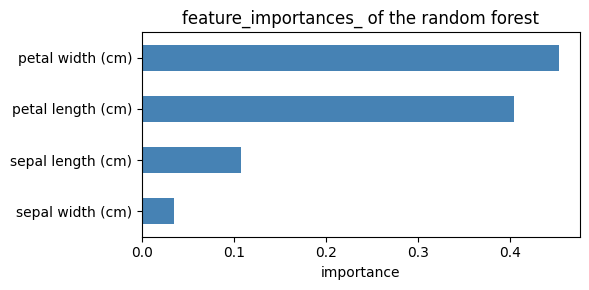

In [24]:
from sklearn.datasets import load_iris
iris = load_iris(as_frame=True)
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.3, random_state=0, stratify=iris.target)

rf = RandomForestClassifier(n_estimators=200, random_state=0).fit(Xi_tr, yi_tr)

print("classes_           :", rf.classes_)
print("n_features_in_     :", rf.n_features_in_)
print("feature_names_in_  :", list(rf.feature_names_in_))
print("Accuracy (score)   :", round(rf.score(Xi_te, yi_te), 4))

proba = rf.predict_proba(Xi_te.iloc[:3])
print("\npredict_proba of first 3 test samples (columns follow classes_):")
print(pd.DataFrame(proba, columns=rf.classes_).round(3))

imp = pd.Series(rf.feature_importances_, index=iris.feature_names).sort_values()
imp.plot.barh(color="steelblue", figsize=(6, 3), title="feature_importances_ of the random forest")
plt.xlabel("importance"); plt.tight_layout(); plt.show()

Feature importances sum to 1 and tell us which measurements the forest relied on most (for Iris, the petal measurements dominate). The row sums of `predict_proba` are 1 as well. Both attributes illustrate the benefit of a shared API: once you know the vocabulary, any classifier can be inspected the same way.

### 6.3 `clone`: copying an estimator's configuration

`sklearn.base.clone()` creates a **new, unfitted** estimator with the same hyperparameters. This is what cross-validation and grid search do internally, so that every fold starts from scratch.

In [25]:
from sklearn.base import clone

fitted = LogisticRegression(C=0.5, max_iter=500).fit(Xb_tr, yb_tr)
copy = clone(fitted)

print("Original has coef_ :", hasattr(fitted, "coef_"))
print("Clone has coef_    :", hasattr(copy, "coef_"))
print("Same hyperparameters:", fitted.get_params() == copy.get_params())

Original has coef_ : True
Clone has coef_    : False
Same hyperparameters: True


## 7. Hyperparameter Tuning with Search Methods

Hyperparameters are the **settings that control how a model learns**; they are not learned from the data. Examples: the number of neighbours $k$ in KNN, the regularisation strength $C$ in logistic regression, or the depth of a tree. Choosing them well often matters as much as choosing the algorithm.

scikit-learn offers:

| Tool | Strategy | When to use |
|:-----|:---------|:------------|
| `set_params()` / `get_params()` | Manual setting and reading | Experimentation |
| `GridSearchCV` | Exhaustive search over a grid | Small search spaces |
| `RandomizedSearchCV` | Random sampling from distributions | Large search spaces |
| `HalvingGridSearchCV` / `HalvingRandomSearchCV` | Successive halving: many candidates on little data, the best get more data | Expensive models |

### 7.1 Manual control: `get_params()` and `set_params()` (book example)

In [26]:
model = RandomForestClassifier()
model.set_params(n_estimators=100, max_depth=10, random_state=42)

params = model.get_params()
for key in ["n_estimators", "max_depth", "max_features", "criterion", "random_state"]:
    print(f"{key:14s}: {params[key]}")
print("... total hyperparameters:", len(params))

n_estimators  : 100
max_depth     : 10
max_features  : sqrt
criterion     : gini
random_state  : 42
... total hyperparameters: 19


`get_params()` returns **all** hyperparameters in a dictionary (including those left at their defaults), which makes it easy to log the exact configuration of an experiment.

For pipelines, `get_params()` also exposes nested parameters using the **double-underscore convention** `<step name>__<parameter>`. That naming is what allows us to tune an entire pipeline.

In [27]:
print([k for k in pipe.get_params().keys() if "__" in k][:8], "...")
pipe.set_params(clf__C=0.1)
print("\nclf__C after set_params:", pipe.get_params()["clf__C"])

['imputer__add_indicator', 'imputer__copy', 'imputer__fill_value', 'imputer__keep_empty_features', 'imputer__missing_values', 'imputer__strategy', 'scaler__copy', 'scaler__with_mean'] ...

clf__C after set_params: 0.1


### 7.2 `GridSearchCV`: exhaustive search with cross-validation

`GridSearchCV` evaluates **every combination** of the supplied values with $k$-fold cross-validation, then refits the best one on the full training set (`refit=True`). Because the pipeline is re-fitted inside each fold, there is no leakage.

In [28]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

pipe_svm = Pipeline([("scaler", StandardScaler()), ("svc", SVC())])

param_grid = {
    "svc__C":      [0.1, 1, 10, 100],
    "svc__gamma":  ["scale", 0.01, 0.1],
    "svc__kernel": ["rbf", "linear"],
}

grid = GridSearchCV(pipe_svm, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(Xb_tr, yb_tr)

print("Number of candidate configurations:", len(grid.cv_results_["params"]))
print("Best parameters  :", grid.best_params_)
print(f"Best CV accuracy : {grid.best_score_:.4f}")
print(f"Held-out test accuracy of refitted best model: {grid.score(Xb_te, yb_te):.4f}")

Number of candidate configurations: 24
Best parameters  : {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best CV accuracy : 0.9802
Held-out test accuracy of refitted best model: 0.9825


The grid contains $4 \times 3 \times 2 = 24$ candidates, each evaluated with 5-fold cross-validation, which is 120 model fits (plus one final refit). That growth is the main weakness of grid search: the cost multiplies with every extra hyperparameter.

All results are kept in `cv_results_`, which is easy to analyse as a DataFrame:

In [29]:
res = pd.DataFrame(grid.cv_results_)
cols = ["param_svc__kernel", "param_svc__C", "param_svc__gamma", "mean_test_score", "std_test_score", "rank_test_score"]
res[cols].sort_values("rank_test_score").head(8).reset_index(drop=True)

,param_svc__kernel,param_svc__C,param_svc__gamma,mean_test_score,std_test_score,rank_test_score
0,rbf,10.0000,0.0100,0.9802,0.0162,1
1,linear,0.1000,scale,0.9780,0.0139,2
2,linear,0.1000,0.1000,0.9780,0.0139,2
3,linear,0.1000,0.0100,0.9780,0.0139,2
4,rbf,10.0000,scale,0.9714,0.0179,5
5,rbf,1.0000,scale,0.9714,0.0179,5
6,rbf,1.0000,0.0100,0.9692,0.0235,7
7,rbf,100.0000,0.0100,0.9692,0.0162,7


Looking at `std_test_score` next to the mean is important: if several configurations are separated by less than one standard deviation, they are statistically indistinguishable, and the simpler one should usually be preferred.

### 7.3 `RandomizedSearchCV`: sampling instead of enumerating

For a large search space, evaluating a fixed budget of **random** configurations is usually far more efficient, especially when only a few hyperparameters really matter. Instead of lists we can pass **distributions** (e.g. log-uniform for $C$).

In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform
import time

param_dist = {
    "svc__C":      loguniform(1e-2, 1e3),
    "svc__gamma":  loguniform(1e-4, 1e0),
    "svc__kernel": ["rbf"],
}

t0 = time.time()
rand = RandomizedSearchCV(pipe_svm, param_dist, n_iter=20, cv=5, scoring="accuracy",
                          random_state=0, n_jobs=-1).fit(Xb_tr, yb_tr)
t_rand = time.time() - t0

print("Best parameters :", {k: (round(v, 5) if isinstance(v, float) else v) for k, v in rand.best_params_.items()})
print(f"Best CV accuracy: {rand.best_score_:.4f}  (20 random candidates, {t_rand:.1f}s)")
print(f"Test accuracy   : {rand.score(Xb_te, yb_te):.4f}")

Best parameters : {'svc__C': np.float64(4.0667), 'svc__gamma': np.float64(0.00456), 'svc__kernel': 'rbf'}
Best CV accuracy: 0.9758  (20 random candidates, 1.0s)
Test accuracy   : 0.9825


With only 20 evaluations the random search explored *continuous* ranges that the grid never touched (the grid only had four values of $C$), and typically reaches similar accuracy. The key advantage: the cost is **fixed by `n_iter`**, not by the size of the search space.

### 7.4 Successive halving

`HalvingGridSearchCV` starts with all candidates but a small amount of data, keeps only the best fraction at each round (`factor=3` means one third), and gives the survivors more resources. It is still *experimental*, so it must be explicitly enabled.

In [31]:
from sklearn.experimental import enable_halving_search_cv  # noqa: F401  (activates the feature)
from sklearn.model_selection import HalvingGridSearchCV

t0 = time.time()
halving = HalvingGridSearchCV(pipe_svm, param_grid, cv=5, factor=3, random_state=0, n_jobs=-1)
halving.fit(Xb_tr, yb_tr)
t_half = time.time() - t0

print("Best parameters :", halving.best_params_)
print(f"Best CV score    : {halving.best_score_:.4f}")
print("Candidates per round:", halving.n_candidates_)
print("Samples per round   :", halving.n_resources_)

Best parameters : {'svc__C': 1, 'svc__gamma': 0.1, 'svc__kernel': 'linear'}
Best CV score    : 0.9733
Candidates per round: [24, 8, 3]
Samples per round   : [50, 150, 450]


The printed lists show the idea clearly: many candidates are examined with few samples first, and only the most promising survive to be evaluated with the full data. This often gives a large speed-up on expensive models, at the cost of a small risk that a configuration that needs more data to shine is dropped early.

## 8. Working with Metadata: Tags and More

scikit-learn uses metadata in two different senses.

### 8.1 Estimator tags

**Tags** are static descriptions of an estimator's capabilities, such as "accepts sparse input" or "tolerates missing values". Meta-estimators and utilities use them to adapt their behaviour. They can be read with `sklearn.utils.get_tags`.

In [32]:
from sklearn.utils import get_tags
from sklearn.ensemble import HistGradientBoostingClassifier

rows = []
for est in [LogisticRegression(), RandomForestClassifier(), HistGradientBoostingClassifier(),
            StandardScaler(), KMeans(n_init=10)]:
    t = get_tags(est)
    rows.append({
        "estimator": type(est).__name__,
        "estimator_type": t.estimator_type,
        "allows NaN": t.input_tags.allow_nan,
        "sparse input": t.input_tags.sparse,
        "requires y": t.target_tags.required,
    })
pd.DataFrame(rows).set_index("estimator")

,estimator_type,allows NaN,sparse input,requires y
estimator,,,,
LogisticRegression,classifier,False,True,True
RandomForestClassifier,classifier,True,True,True
HistGradientBoostingClassifier,classifier,True,False,True
StandardScaler,NaN,True,False,False
KMeans,clusterer,False,True,False


The table shows, for example, that `HistGradientBoostingClassifier` accepts `NaN` values natively (no imputation needed), that `StandardScaler` has no estimator type (it is a transformer), and that clustering algorithms do not require `y`. Custom estimators can override tags through the `__sklearn_tags__` method.

### 8.2 Metadata routing

The second kind of metadata is **per-sample information passed through `fit()`**: sample weights, group labels for grouped cross-validation, and so on. **Metadata routing** lets a meta-estimator (a *router*, e.g. `Pipeline` or `GridSearchCV`) forward this information to the sub-estimators that *consume* it, and only to those.

For example, with imbalanced data we may want `sample_weight` to reach the classifier but **not** the scaler. Routing is disabled by default for backward compatibility, so we enable it and declare explicitly which step requests what with `set_fit_request`.

In [33]:
from sklearn import config_context

rng = np.random.default_rng(3)
w = np.where(yb_tr == 0, 3.0, 1.0)         # up-weight the minority class (malignant = 0)

with config_context(enable_metadata_routing=True):
    scaler = StandardScaler().set_fit_request(sample_weight=False)         # scaler ignores weights
    clf = LogisticRegression(max_iter=2000).set_fit_request(sample_weight=True)   # classifier uses them
    routed = Pipeline([("scaler", scaler), ("clf", clf)])
    routed.fit(Xb_tr, yb_tr, sample_weight=w)                              # one call, routed correctly

plain = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)).fit(Xb_tr, yb_tr)

from sklearn.metrics import recall_score
print("Recall of the minority class (malignant) on the test set:")
print(f"  without weights : {recall_score(yb_te, plain.predict(Xb_te), pos_label=0):.4f}")
print(f"  with routed sample_weight: {recall_score(yb_te, routed.predict(Xb_te), pos_label=0):.4f}")

# The recall is similar because this dataset is easy; verify that the weights really reached the classifier
coef_diff = np.abs(routed[-1].coef_ - plain[-1].coef_).max()
print(f"\nLargest absolute difference between the two models' coefficients: {coef_diff:.4f}")
print("-> non-zero difference proves that sample_weight was routed to the classifier")

Recall of the minority class (malignant) on the test set:
  without weights : 0.9762
  with routed sample_weight: 0.9762

Largest absolute difference between the two models' coefficients: 0.6879
-> non-zero difference proves that sample_weight was routed to the classifier


The recall values are similar because this dataset is easy to separate; what matters is that the coefficients **do** differ, proving that the weights reached the classifier while the scaler ignored them.

Without routing, passing `sample_weight` to the pipeline would raise an error (because the pipeline cannot know which step should receive it). With routing, each step declares whether it wants the metadata, and the pipeline forwards it appropriately. The same mechanism lets `GridSearchCV` and `cross_validate` pass `groups` to group-aware splitters. We will see practical uses in Chapters 12 and 13.

## 9. Best Practices for API Usage

| # | Practice | Why it matters |
|:-:|:---------|:---------------|
| 1 | **Use the uniform API** (`fit`, `predict`, `transform`) and avoid custom wrappers | Readability and easy model swapping |
| 2 | **Split first, then preprocess** | Prevents data leakage |
| 3 | **Fit transformers on training data only** | The test set must stay unseen |
| 4 | **Wrap preprocessing and the model in a `Pipeline`** | Guarantees order and correct cross-validation |
| 5 | **Use `ColumnTransformer` for mixed data types** | Different columns need different treatment |
| 6 | **Tune with cross-validation** (`GridSearchCV`, `RandomizedSearchCV`) | Honest estimates of generalisation |
| 7 | **Set `random_state`** wherever randomness occurs | Reproducible experiments |
| 8 | **Inspect fitted attributes** (`coef_`, `feature_importances_`) | Interpretability and debugging |
| 9 | **Keep components modular** (custom transformers instead of notebook spaghetti) | Reuse and testing |
| 10 | **Persist the whole pipeline** (e.g. with `joblib`), not only the model | Deployment must repeat preprocessing exactly |

### A final demonstration: reproducibility with `random_state`

Randomised algorithms give different results on every run unless the seed is fixed. Fixing `random_state` makes an experiment repeatable, which is essential when comparing models or reporting results.

In [34]:
accs_unseeded = [RandomForestClassifier(n_estimators=10).fit(Xi_tr, yi_tr).score(Xi_te, yi_te) for _ in range(5)]
accs_seeded   = [RandomForestClassifier(n_estimators=10, random_state=0).fit(Xi_tr, yi_tr).score(Xi_te, yi_te) for _ in range(5)]

print("Without random_state:", np.round(accs_unseeded, 4), "-> may vary between runs")
print("With    random_state:", np.round(accs_seeded, 4), "-> identical every time")

Without random_state: [0.9556 0.9778 0.9778 0.9556 1.    ] -> may vary between runs
With    random_state: [0.9778 0.9778 0.9778 0.9778 0.9778] -> identical every time


## Summary

- scikit-learn's power comes from **consistent conventions**: estimators learn with `fit()`, predictors use `predict()`, transformers use `transform()`; hyperparameters are constructor arguments, learned values end with an underscore.
- **Transformers** must be fitted on training data only. Re-fitting on test data or fitting before splitting causes **data leakage** (we measured how it can fake high accuracy on random data).
- **Custom estimators** need only `BaseEstimator` plus the right mixin(s); they then work in pipelines, grid searches and cross-validation.
- **Pipelines** and `ColumnTransformer` encapsulate the whole workflow in one object, making experiments correct, compact and deployable.
- **Common attributes** such as `coef_`, `classes_`, and `feature_importances_` provide a uniform way to inspect models.
- **Search methods** (`GridSearchCV`, `RandomizedSearchCV`, halving searches) automate hyperparameter tuning, and nested parameter names (`step__param`) allow tuning an entire pipeline.
- **Tags** describe estimator capabilities; **metadata routing** forwards sample-level information (like weights) to only those steps that consume it.

In **Chapter 2** we apply these conventions to the most important (and most underrated) part of the ML workflow: preparing the data.